<!-- ===================== APPROACH HEADER ===================== -->
<h1 id="approach" style="
  background: linear-gradient(135deg, #0f2027, #203a43, #2c5364);
  color: white;
  padding: 14px 26px;
  border-radius: 12px;
  font-size: 24px;
  font-weight: bold;
  text-align: center;
  font-family: Arial, sans-serif;
  margin: 20px 0;
">
🧠 Approach: ProtLearn-Features
</h1>

<!-- ===================== MAIN CONTAINER ===================== -->
<div style="
  background: white;
  border-radius: 12px;
  border: 1px solid #e0e0e0;
  font-family: Arial, sans-serif;
  color: #333;
  padding: 20px;
  font-size: 15px;
  line-height: 1.6;
  margin-bottom: 25px;
">

  <p>
    The central idea of this approach is to represent protein sequences using
    <strong>ProtLearn</strong>, a bioinformatics-focused Python library designed for extracting
    features from amino acid sequences.
  </p>

  <p>
    ProtLearn implements a collection of well-established protein descriptors that encode
    sequence composition, local residue patterns, physicochemical properties, and positional
    distributions. Each descriptor family captures a different aspect of protein structure
    and function, allowing raw sequences to be transformed into meaningful numerical vectors.
  </p>

  <p>
    In this notebook, multiple ProtLearn feature groups are computed independently and
    concatenated to form a single <strong>695-dimensional representation</strong> per protein.
    These representations serve as the input to a multi-label classifier that
    predicts Gene Ontology (GO) terms.
  </p>


  <p style="margin-bottom: 0;">
    📘 <strong>ProtLearn Documentation:</strong>
    <a href="https://protlearn.readthedocs.io/en/latest/"
       style="color: #2c5364; font-weight: bold; text-decoration: none;">
      https://protlearn.readthedocs.io/
    </a><br>
    🐙 <strong>ProtLearn GitHub:</strong>
    <a href="https://github.com/tadorfer/protlearn"
       style="color: #2c5364; font-weight: bold; text-decoration: none;">
      https://github.com/taylor-joren/protlearn
    </a>
  </p>

</div>


In [1]:
!pip install protlearn obonet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.4/106.4 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 64.8 MB/s eta 0:00:00


<h1 id="import"
    style="
  background: linear-gradient(135deg, #0f2027, #203a43, #2c5364);
  color: white;
  padding: 12px 24px;
  text-align: center;
  border-radius: 12px;
  font-size: 22px;
  font-weight: bold;
  font-family: Arial, sans-serif;
  margin: 20px 0;
">
  1. Importing Libraries
</h1>

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from Bio import SeqIO
from collections import Counter
import gc

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression

from protlearn.features import (
    length, aac, ngram, entropy, 
    ctdc, ctdt, ctdd,
    paac, apaac,
    moreau_broto, moran, geary
)
from protlearn.preprocessing import remove_unnatural, remove_duplicates

import obonet
import torch
from torch import nn
import networkx as nx
from torch.utils.data import Dataset, DataLoader, random_split
from torchmetrics.classification import MultilabelF1Score

from matplotlib import pyplot as plt

warnings.filterwarnings("ignore")


<h1 id="configuration"
    style="
  background: linear-gradient(135deg, #0f2027, #203a43, #2c5364);
  color: white;
  padding: 12px 24px;
  text-align: center;
  border-radius: 12px;
  font-size: 22px;
  font-weight: bold;
  font-family: Arial, sans-serif;
  margin: 20px 0;
">
  2. Configurations
</h1>

In [3]:
class Config:
    IA_path  = "/kaggle/input/cafa-6-protein-function-prediction/IA.tsv"
    train_terms_path = "/kaggle/input/cafa-6-protein-function-prediction/Train/train_terms.tsv"
    train_taxonomy = "/kaggle/input/cafa-6-protein-function-prediction/Train/train_taxonomy.tsv"
    train_sequences = "/kaggle/input/cafa-6-protein-function-prediction/Train/train_sequences.fasta"
    obo_path = "/kaggle/input/cafa-6-protein-function-prediction/Train/go-basic.obo"
    test_sequences = "/kaggle/input/cafa-6-protein-function-prediction/Test/testsuperset.fasta"

    test_features = "/kaggle/input/protlearn-features/X_test_data.pkl"
    train_features = "/kaggle/input/protlearn-features/X_train_data.pkl"

    # Model architecture
    input_dim = 695    
    num_labels = 500     
    hidden_dims = [1024, 512, 512]  
    dropout = 0.3         

    # Training parameters
    batch_size = 128
    train_split = 0.9    
    lr = 1e-3             
    epochs = 100
    patience = 15         

    # Device configuration
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    seed = 42

config = Config()

<!-- ===================== SEQUENCE PREPROCESSING ===================== -->
<h1 id="sequence-preprocessing" style="
  background: linear-gradient(135deg, #1c2b36, #2c3e50, #34495e);
  color: white;
  padding: 14px 26px;
  border-radius: 12px;
  font-size: 22px;
  font-weight: bold;
  text-align: center;
  font-family: Arial, sans-serif;
  margin: 20px 0;
">
3. Sequence Loading and Cleaning
</h1>

<div style="
  background: white;
  border-radius: 12px;
  border: 1px solid #e0e0e0;
  font-family: Arial, sans-serif;
  color: #333;
  padding: 20px;
  font-size: 15px;
  line-height: 1.6;
  margin-bottom: 25px;
">

  <p>
    Protein sequences are loaded from FASTA files and converted into a pandas DataFrame
    containing UniProt entry IDs and raw amino acid sequences.
  </p>

  <p>
    ProtLearn only accepts sequences composed of the <strong>20 standard amino acids</strong>.
    However, the dataset includes some non-standard or ambiguous residues that must be
    resolved prior to feature extraction.
  </p>

  <p>
    To ensure valid ProtLearn input, the following cleaning rules are applied:
  </p>

  <ul>
    <li>
      <strong>U → C</strong>
      (selenocysteine — the rare <em>21st amino acid</em> — mapped to cysteine due to chemical similarity)
    </li>
    <li>
      <strong>B → D</strong>
      (ambiguous residue representing either aspartic acid or asparagine, resolved to aspartic acid)
    </li>
    <li>
      <strong>Z → E</strong>
      (ambiguous residue representing either glutamic acid or glutamine, resolved to glutamic acid)
    </li>
    <li>
      <strong>X → removed</strong>
      (unknown or masked amino acid with no biological specificity)
    </li>
  </ul>

  <p style="margin-bottom: 0;">
    After cleaning, all sequences strictly follow the standard amino acid alphabet and are
    fully compatible with ProtLearn feature extraction.
  </p>

</div>


In [4]:
def load_fasta_as_dataframe(fasta_path: str, train_data:bool = True):
    ids,sequences = [],[]

    for record in SeqIO.parse(fasta_path, "fasta"):
        if train_data:
            uniprot_id = record.id.split("|")[1]
        else:
            uniprot_id = record.id
            
        ids.append(uniprot_id)
        sequences.append(str(record.seq))

    return pd.DataFrame({
        "EntryID": ids,
        "sequences": sequences
    })
    

#Handling non standard Amino acid residues

def clean_sequence(seq):
    return (
        seq.replace("U", "C")   # selenocysteine → cysteine
           .replace("B", "D")   # Asp/Asn → Asp
           .replace("Z", "E")   # Glu/Gln → Glu
           .replace("X", "")    # remove unknowns
    )



<!-- ===================== FEATURE EXTRACTION ===================== -->
<h1 id="feature-extraction" style="
  background: linear-gradient(135deg, #0f2027, #203a43, #2c5364);
  color: white;
  padding: 14px 26px;
  border-radius: 12px;
  font-size: 22px;
  font-weight: bold;
  text-align: center;
  font-family: Arial, sans-serif;
  margin: 20px 0;
">
4. Feature Extraction with ProtLearn
</h1>

<div style="
  background: white;
  border-radius: 12px;
  border: 1px solid #e0e0e0;
  font-family: Arial, sans-serif;
  color: #333;
  padding: 20px;
  font-size: 15px;
  line-height: 1.6;
  margin-bottom: 25px;
">

  <p>
    Cleaned protein sequences are converted into fixed-length numerical representations
    using <strong>ProtLearn</strong>, a feature-engineering library for protein sequence analysis.
  </p>

  <p>
    For each protein, multiple complementary feature groups are extracted and concatenated
    into a single vector.
  </p>

  <ul>
    <li>
      <strong>Sequence Length (1):</strong>
      Total number of amino acids in the protein.
    </li>
    <li>
      <strong>Amino Acid Composition – AAC (20):</strong>
      Relative frequency of each standard amino acid.
    </li>
    <li>
      <strong>Dipeptide Composition (400):</strong>
      Frequency of all possible adjacent amino acid pairs.
    </li>
    <li>
      <strong>Shannon Entropy (1):</strong>
      Measures sequence complexity and variability.
    </li>
    <li>
      <strong>CTD Features:</strong>
      Physicochemical descriptors capturing amino acid
      <em>composition</em>, <em>transition</em>, and <em>distribution</em>
      along the sequence.
    </li>
  </ul>

  <p>
    All feature groups are horizontally concatenated, resulting in a
    <strong>695-dimensional feature vector per protein</strong>.
  </p>



</div>


In [5]:
def extract_features(sequences):
    """
    Extract  feature set from protein sequences.
    
    Args:
        sequences: List of protein sequences (strings)
    
    Returns:
        numpy array of shape (n_proteins, 695) containing all features
    """
    
    # 1. Length - basic sequence length (1 feature)
    X_len = length(sequences)
    
    # 2. Amino Acid Composition - frequency of each amino acid (20 features)
    X_aac, _ = aac(sequences, method='relative')
    
    # 3. Dipeptide Composition - frequency of amino acid pairs (400 features)
    X_di, _ = ngram(sequences, n=2)
    
    # 4. Shannon Entropy - measure of sequence complexity (1 feature)
    X_entropy = entropy(sequences)
    
    # 5. Composition-Transition-Distribution (CTD) Features
    # These capture physicochemical properties of amino acids
    X_ctdc, _ = ctdc(sequences)  # Composition
    X_ctdt, _ = ctdt(sequences)  # Transition between property groups
    X_ctdd, _ = ctdd(sequences)  # Distribution of properties along sequence
    
    # Combine all features horizontally
    features = [X_len, X_aac, X_di, X_entropy, X_ctdc, X_ctdt, X_ctdd]
    X_all = np.hstack(features)
    
    print(f"\n✓ Feature extraction complete. Shape: {X_all.shape}")
    print(f"  Total features per protein: {X_all.shape[1]}")
    
    return X_all


# # Load sequences
# train_sequences_df = load_fasta_as_dataframe(config.train_sequences, train_data=True)
# test_sequences_df = load_fasta_as_dataframe(config.test_sequences, train_data=False)

# # Clean sequences
# train_sequences_df["sequences"] = train_sequences_df["sequences"].apply(clean_sequence)
# test_sequences_df["sequences"] = test_sequences_df["sequences"].apply(clean_sequence)

# # Extract features
# train_sequences_list = train_sequences_df['sequences'].tolist()
# test_sequences_list = test_sequences_df['sequences'].tolist()

# X_train = extract_features(train_sequences_list)
# X_test = extract_features(test_sequences_list)


# print("✓ Features saved successfully!")

<!-- ===================== FEATURE & LABEL PREPARATION ===================== -->
<h1 id="feature-label-preparation" style="
  background: linear-gradient(135deg, #16222a, #3a6073);
  color: white;
  padding: 14px 26px;
  border-radius: 12px;
  font-size: 22px;
  font-weight: bold;
  text-align: center;
  font-family: Arial, sans-serif;
  margin: 20px 0;
">
5. Feature and Label Preparation
</h1>

<div style="
  background: white;
  border-radius: 12px;
  border: 1px solid #e0e0e0;
  font-family: Arial, sans-serif;
  color: #333;
  padding: 20px;
  font-size: 15px;
  line-height: 1.6;
  margin-bottom: 25px;
">

  <p style="margin-bottom: 0;">
    Precomputed ProtLearn features are loaded from disk and aligned using UniProt
    EntryIDs, while Gene Ontology (GO) annotations are grouped per protein to form
    multi-label targets. To account for the hierarchical nature of GO, each annotated
    term is expanded to include all its ancestor terms using the GO graph, after which
    only the top N most frequent GO terms are retained. These propagated label sets are
    then binarized into fixed-length target vectors and merged with the ProtLearn
    feature matrix to construct the final training dataset,
  </p>

</div>


In [6]:
train_features_df = pd.read_pickle(config.train_features).rename({"ID":"EntryID"}, axis=1)
test_features_df = pd.read_pickle(config.test_features).rename({"ID":"EntryID"}, axis=1)

print(f"train_features_df shape: {train_features_df.shape}")
print(f"test_features_df shape:  {test_features_df.shape}")

# Load GO term labels
train_terms_df = pd.read_csv(config.train_terms_path, sep="\t")

# Group GO terms by protein ID
labels_df = (
    train_terms_df
    .groupby("EntryID")["term"]
    .apply(list)
    .reset_index(name="labels")
)


go_graph = obonet.read_obo(config.obo_path)

def get_ancestors(graph, term):
    if term not in graph:
        return set()
    return nx.descendants(graph, term) | {term}

print("\n" + "="*60)
print("PROPAGATING GO TERM ANCESTORS")
print("="*60)

# Select top N most frequent GO terms
top_go = (
    train_terms_df["term"]
    .value_counts()
    .iloc[:config.num_labels]
    .index
    .tolist()
)
top_go_set = set(top_go)

# Group GO terms by protein ID
protein_to_terms = train_terms_df.groupby("EntryID")["term"].apply(set).to_dict()

# Propagate ancestors for each protein
propagated_labels = {}
print("Propagating ancestors for each protein...")

for protein_id, terms in tqdm(protein_to_terms.items(), desc="Propagating"):
    all_ancestors = set()
    for term in terms:
        # Get all ancestors for this term
        ancestors = get_ancestors(go_graph, term)
        all_ancestors.update(ancestors)
    
    # Filter to only keep terms in our top N list
    propagated_labels[protein_id] = all_ancestors.intersection(top_go_set)

# Create labels DataFrame with propagated terms
labels_data = []
for protein_id, terms in propagated_labels.items():
    if terms:  # Only include proteins with at least one term
        labels_data.append({
            "EntryID": protein_id,
            "labels": list(terms)
        })

labels_df = pd.DataFrame(labels_data)


print("\n" + "="*60)
print("PREPROCESSING DATA")
print("="*60)

# Initialize MultiLabelBinarizer for one-hot encoding GO terms
mlb = MultiLabelBinarizer(classes=top_go)
mlb.fit([top_go])

# Convert GO term lists to binary target vectors
labels_df["targets"] = list(mlb.transform(labels_df["labels"]))

# Create training DataFrame with embeddings and labels


train_df = train_features_df.merge(labels_df, on="EntryID", how="inner")

# Create test DataFrame
test_df = test_features_df 

print(f"Training data shape: {train_df.shape}")
print(f"Test data shape: {test_df.shape}")

train_features_df shape: (82404, 2)
test_features_df shape:  (224309, 2)

PROPAGATING GO TERM ANCESTORS
Propagating ancestors for each protein...


Propagating:   0%|          | 0/82404 [00:00<?, ?it/s]


PREPROCESSING DATA
Training data shape: (78699, 4)
Test data shape: (224309, 2)


<!-- ===================== MODEL ARCHITECTURE ===================== -->
<h1 id="model-architecture" style="
  background: linear-gradient(135deg, #0f2027, #203a43, #2c5364);
  color: white;
  padding: 14px 26px;
  border-radius: 12px;
  font-size: 22px;
  font-weight: bold;
  text-align: center;
  font-family: Arial, sans-serif;
  margin: 20px 0;
">
6. Model Architecture
</h1>

<div style="
  background: white;
  border-radius: 12px;
  border: 1px solid #e0e0e0;
  font-family: Arial, sans-serif;
  color: #333;
  padding: 20px;
  font-size: 15px;
  line-height: 1.6;
  margin-bottom: 25px;
">

  <p style="margin-bottom: 0;">
    The model is a fully connected multi-layer perceptron (MLP) designed for
    multi-label protein function prediction. It consists of stacked hidden layers
    with batch normalization, ReLU activations, and dropout for regularization.
    Residual connections are added every two layers to facilitate gradient flow
    and improve training stability. The output layer maps to the fixed set of
    selected Gene Ontology terms, producing one score per label for each protein.
  </p>

</div>


In [7]:
class MLP(nn.Module):
    
    def __init__(self, input_dim=1024, num_labels=500, hidden_dims=[1024, 512, 512], dropout=0.3):
        super().__init__()
        self.layers = nn.ModuleList()
        self.bns = nn.ModuleList()
        self.dropouts = nn.ModuleList()

        # Build hidden layers
        prev_dim = input_dim
        for h in hidden_dims:
            self.layers.append(nn.Linear(prev_dim, h))
            self.bns.append(nn.BatchNorm1d(h))
            self.dropouts.append(nn.Dropout(dropout))
            prev_dim = h

        # Output layer
        self.out = nn.Linear(prev_dim, num_labels)

    def forward(self, x):
        residual = x
        
        # Pass through hidden layers with residual connections
        for i, layer in enumerate(self.layers):
            x = layer(x)
            x = self.bns[i](x)
            x = torch.relu(x)
            x = self.dropouts[i](x)
            
            # Add residual connection every 2 layers
            if i % 2 == 1:
                if residual.shape[1] == x.shape[1]:
                    x = x + residual
                residual = x
            else:
                residual = x
        
        # Output layer
        x = self.out(x)
        return x

<!-- ===================== DATASET & DATALOADERS ===================== -->
<h1 id="dataset-dataloaders" style="
  background: linear-gradient(135deg, #16222a, #3a6073);
  color: white;
  padding: 14px 26px;
  border-radius: 12px;
  font-size: 22px;
  font-weight: bold;
  text-align: center;
  font-family: Arial, sans-serif;
  margin: 20px 0;
">
7. Dataset and Data Loading
</h1>

<div style="
  background: white;
  border-radius: 12px;
  border: 1px solid #e0e0e0;
  font-family: Arial, sans-serif;
  color: #333;
  padding: 20px;
  font-size: 15px;
  line-height: 1.6;
  margin-bottom: 25px;
">

  <p style="margin-bottom: 0;">
    A custom PyTorch dataset is defined to serve ProtLearn feature vectors and
    multi-label GO targets, returning feature–label pairs during training and
    feature–ID pairs during inference. The full training set is split into
    training and validation subsets using a fixed random seed to ensure
    reproducibility, and DataLoaders are constructed for efficient mini-batch
    processing with shuffling applied only to the training data.
  </p>

</div>


In [8]:
class ProteinFunctionDataset(Dataset):
    """Custom Dataset for protein embeddings and GO term labels"""
    
    def __init__(self, df, train=True):
        self.df = df.reset_index(drop=True)
        self.train = train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        embed = torch.tensor(self.df.loc[idx, "features"], dtype=torch.float32)
        
        if self.train:
            target = torch.tensor(self.df.loc[idx, "targets"], dtype=torch.float32)
            return embed, target
        else:
            entry_id = self.df.loc[idx, "EntryID"]
            return embed, entry_id

# Create datasets
full_train_dataset = ProteinFunctionDataset(train_df, train=True)
test_dataset = ProteinFunctionDataset(test_df, train=False)

# Split training data into train and validation sets
train_size = int(len(full_train_dataset) * config.train_split)
val_size = len(full_train_dataset) - train_size

g = torch.Generator().manual_seed(config.seed)
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size], generator=g)

# Create dataloaders
train_loader = DataLoader(train_dataset, batch_size=config.batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=config.batch_size, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=config.batch_size, shuffle=False)

print(f"\nTrain batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")



Train batches: 554
Validation batches: 62
Test batches: 1753


<!-- ===================== MODEL TRAINING ===================== -->
<h1 id="model-training" style="
  background: linear-gradient(135deg, #0f2027, #203a43, #2c5364);
  color: white;
  padding: 14px 26px;
  border-radius: 12px;
  font-size: 22px;
  font-weight: bold;
  text-align: center;
  font-family: Arial, sans-serif;
  margin: 20px 0;
">
8. Model Training
</h1>

<div style="
  background: white;
  border-radius: 12px;
  border: 1px solid #e0e0e0;
  font-family: Arial, sans-serif;
  color: #333;
  padding: 20px;
  font-size: 15px;
  line-height: 1.6;
  margin-bottom: 25px;
">

  <p style="margin-bottom: 0;">
    The MLP model is trained using mini-batch gradient descent with the Adam optimizer,
    applying cross-entropy loss for multi-label classification. Training proceeds over
    multiple epochs, with performance evaluated on a validation set at each epoch using
    F1 score. A learning rate scheduler adapts the optimizer based on validation loss, and
    early stopping is implemented to save the model checkpoint corresponding to the best
    validation performance, preventing overfitting and ensuring optimal generalization.
  </p>

</div>


In [9]:
def train_model(model, train_loader, val_loader, cfg, save_path="best_model.pt"):
  
    
    model.to(config.device)

    # Initialize optimizer, scheduler, and loss function
    optimizer = torch.optim.Adam(model.parameters(), lr=config.lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )
    loss_fn = nn.CrossEntropyLoss()
    # loss_fn = nn.BCEWithLogitsLoss() 
    f1_score = MultilabelF1Score(num_labels=config.num_labels).to(config.device)

    # Tracking metrics
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_f1": [],
        "val_f1": []
    }

    best_val_loss = float("inf")
    patience_counter = 0

    print("\n" + "="*60)
    print("TRAINING")
    print("="*60)

    for epoch in range(config.epochs):
        # ===== TRAINING PHASE =====
        model.train()
        train_losses, train_f1s = [], []

        for embeds, targets in train_loader:
            embeds = embeds.to(config.device)
            targets = targets.to(config.device)

            # Forward pass
            optimizer.zero_grad()
            logits = model(embeds)
            loss = loss_fn(logits, targets)
            
            # Backward pass
            loss.backward()
            optimizer.step()

            # Calculate metrics
            f1 = f1_score(logits, targets)
            train_losses.append(loss.item())
            train_f1s.append(f1.item())

        avg_train_loss = np.mean(train_losses)
        avg_train_f1 = np.mean(train_f1s)

        # ===== VALIDATION PHASE =====
        model.eval()
        val_losses, val_f1s = [], []

        with torch.no_grad():
            for embeds, targets in val_loader:
                embeds = embeds.to(config.device)
                targets = targets.to(config.device)

                logits = model(embeds)
                loss = loss_fn(logits, targets)

                f1 = f1_score(logits, targets)
                val_losses.append(loss.item())
                val_f1s.append(f1.item())

        avg_val_loss = np.mean(val_losses)
        avg_val_f1 = np.mean(val_f1s)

        # Save metrics
        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        history["train_f1"].append(avg_train_f1)
        history["val_f1"].append(avg_val_f1)

        # Print progress
        print(
            f"Epoch {epoch+1:3d}/{cfg.epochs} | "
            f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | "
            f"Train F1: {avg_train_f1:.4f} | Val F1: {avg_val_f1:.4f}"
        )

        # Learning rate scheduling
        scheduler.step(avg_val_loss)

        # ===== CHECKPOINTING & EARLY STOPPING =====
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            patience_counter = 0
            torch.save(model.state_dict(), save_path)
            print(f"💾 Best model saved at epoch {epoch+1}")
        else:
            patience_counter += 1
            print(f"⏳ No improvement. Patience: {patience_counter}/{config.patience}")

        if patience_counter >= cfg.patience:
            print("🛑 Early stopping triggered.")
            break

    print(f"\n✅ Training complete! Best Val Loss: {best_val_loss:.4f}")
    return history


model = MLP(
    input_dim=config.input_dim,
    num_labels=config.num_labels,
    hidden_dims=config.hidden_dims,
    dropout=config.dropout
)

history = train_model(model, train_loader, val_loader, config, save_path="best_model.pt")



TRAINING
Epoch   1/100 | Train Loss: 46.0604 | Val Loss: 48.0747 | Train F1: 0.0374 | Val F1: 0.0391
💾 Best model saved at epoch 1
Epoch   2/100 | Train Loss: 44.9065 | Val Loss: 47.0221 | Train F1: 0.0478 | Val F1: 0.0396
💾 Best model saved at epoch 2
Epoch   3/100 | Train Loss: 44.4984 | Val Loss: 46.4110 | Train F1: 0.0525 | Val F1: 0.0426
💾 Best model saved at epoch 3
Epoch   4/100 | Train Loss: 44.1966 | Val Loss: 45.6640 | Train F1: 0.0565 | Val F1: 0.0488
💾 Best model saved at epoch 4
Epoch   5/100 | Train Loss: 43.9645 | Val Loss: 45.2251 | Train F1: 0.0594 | Val F1: 0.0568
💾 Best model saved at epoch 5
Epoch   6/100 | Train Loss: 43.7326 | Val Loss: 48.1981 | Train F1: 0.0622 | Val F1: 0.0472
⏳ No improvement. Patience: 1/15
Epoch   7/100 | Train Loss: 43.5406 | Val Loss: 49.0926 | Train F1: 0.0648 | Val F1: 0.0458
⏳ No improvement. Patience: 2/15
Epoch   8/100 | Train Loss: 43.3838 | Val Loss: 46.2766 | Train F1: 0.0668 | Val F1: 0.0534
⏳ No improvement. Patience: 3/15
Epoch

<!-- ===================== TRAINING VISUALIZATION ===================== -->
<h1 id="training-visualization" style="
  background: linear-gradient(135deg, #0f2027, #203a43, #2c5364);
  color: white;
  padding: 14px 26px;
  border-radius: 12px;
  font-size: 22px;
  font-weight: bold;
  text-align: center;
  font-family: Arial, sans-serif;
  margin: 20px 0;
">
9. Training Visualization
</h1>

<div style="
  background: white;
  border-radius: 12px;
  border: 1px solid #e0e0e0;
  font-family: Arial, sans-serif;
  color: #333;
  padding: 20px;
  font-size: 15px;
  line-height: 1.6;
  margin-bottom: 25px;
">

  <p style="margin-bottom: 0;">
    Training progress is visualized by plotting both loss and F1 score over epochs
    for the training and validation sets. These plots provide insight into model
    convergence, performance trends, and potential overfitting. 
  </p>

</div>



📊 Training history plot saved to training_history.png


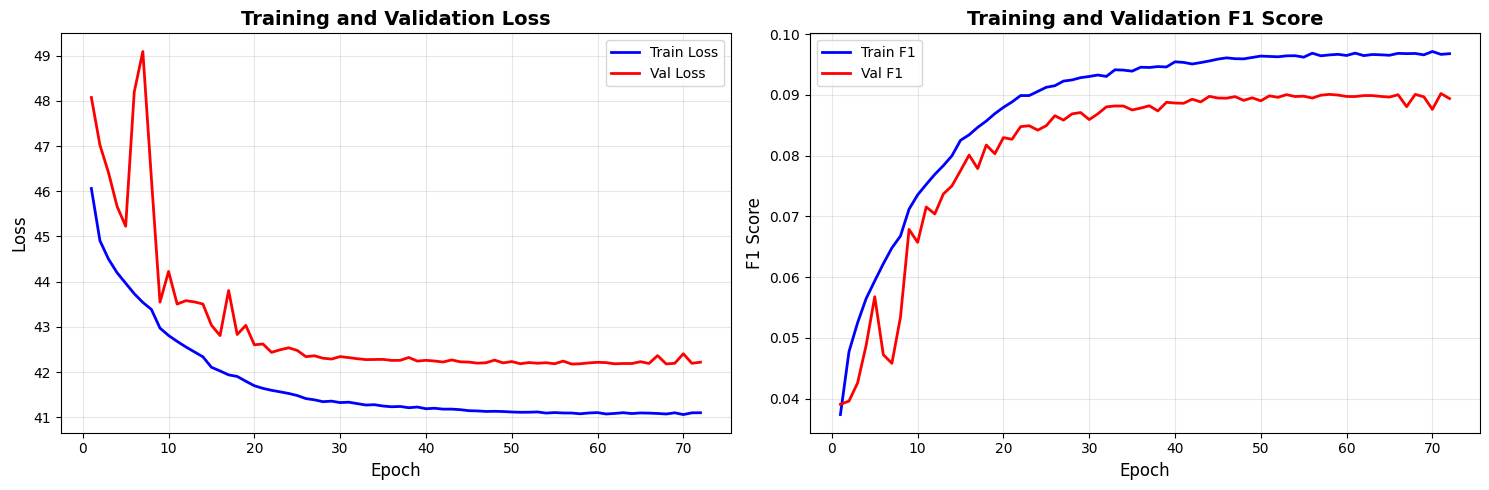

In [10]:
# VISUALIZATION
def plot_training_history(history, save_path="training_history.png"):
    """Plot training and validation metrics"""
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    
    epochs = range(1, len(history["train_loss"]) + 1)
    
    # Loss plot
    ax1.plot(epochs, history["train_loss"], 'b-', label="Train Loss", linewidth=2)
    ax1.plot(epochs, history["val_loss"], 'r-', label="Val Loss", linewidth=2)
    ax1.set_xlabel("Epoch", fontsize=12)
    ax1.set_ylabel("Loss", fontsize=12)
    ax1.set_title("Training and Validation Loss", fontsize=14, fontweight='bold')
    ax1.legend(fontsize=10)
    ax1.grid(True, alpha=0.3)
    
    # F1 score plot
    ax2.plot(epochs, history["train_f1"], 'b-', label="Train F1", linewidth=2)
    ax2.plot(epochs, history["val_f1"], 'r-', label="Val F1", linewidth=2)
    ax2.set_xlabel("Epoch", fontsize=12)
    ax2.set_ylabel("F1 Score", fontsize=12)
    ax2.set_title("Training and Validation F1 Score", fontsize=14, fontweight='bold')
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"\n📊 Training history plot saved to {save_path}")
    plt.show()



# Plot training history
plot_training_history(history)


<!-- ===================== INFERENCE & SUBMISSION ===================== -->
<h1 id="inference-submission" style="
  background: linear-gradient(135deg, #0f2027, #203a43, #2c5364);
  color: white;
  padding: 14px 26px;
  border-radius: 12px;
  font-size: 22px;
  font-weight: bold;
  text-align: center;
  font-family: Arial, sans-serif;
  margin: 20px 0;
">
10. Inference and Submission Generation
</h1>

<div style="
  background: white;
  border-radius: 12px;
  border: 1px solid #e0e0e0;
  font-family: Arial, sans-serif;
  color: #333;
  padding: 20px;
  font-size: 15px;
  line-height: 1.6;
  margin-bottom: 25px;
">

  <p style="margin-bottom: 0;">
    The trained MLP model is loaded from the best checkpoint and used to predict
    Gene Ontology term probabilities for all test proteins. Predictions are
    computed in mini-batches, with a sigmoid applied to produce probabilities
    for each GO label. For each protein, only terms with positive probability
    are retained, sorted by confidence, and truncated to a maximum per-protein
    limit. Probabilities are formatted to three significant figures, and the
    resulting predictions are saved in tab-separated format for submission.
  </p>

</div>


In [11]:
# Load the best model checkpoint saved during training
model.load_state_dict(torch.load("best_model.pt", map_location=config.device))
print("✅ Best model loaded successfully!")

def generate_submission(
    model,
    test_loader,
    go_terms,
    device,
    output_path="submission.tsv",
    max_terms_per_protein=1500,
    min_prob=1e-6
):
   
    
    model.eval()
    
    all_ids = []
    all_probs = []

    # Generate predictions
    with torch.no_grad():
        for embeds, ids in tqdm(test_loader, desc="Predicting"):
            embeds = embeds.to(device)
            logits = model(embeds)
            probs = torch.sigmoid(logits).cpu().numpy()

            all_probs.append(probs)
            all_ids.extend(ids)

    all_probs = np.vstack(all_probs)  # Shape: (N_test, num_labels)
    all_ids = np.array(all_ids)

    # Format predictions for submission
    rows = []

    for i, prot_id in enumerate(all_ids):
        probs = all_probs[i]

        # Keep only positive probabilities
        idx = np.where(probs > 0)[0]
        if len(idx) == 0:
            continue

        # Sort by confidence (descending)
        idx = idx[np.argsort(probs[idx])[::-1]]

        # Limit to top 1500 terms per protein 
        idx = idx[:max_terms_per_protein]

        for j in idx:
            p = probs[j]
            if p <= 0:
                continue

            # Format to 3 significant figures 
            p_fmt = float(f"{p:.3g}")
            if p_fmt <= 0:
                p_fmt = min_prob

            rows.append([prot_id, go_terms[j], p_fmt])

    # Create submission DataFrame
    sub_df = pd.DataFrame(rows)
    sub_df.to_csv(output_path, sep="\t", header=False, index=False)

    print(f"\n✅ Submission saved to {output_path}")
    print(f"Total predictions: {len(sub_df):,}")

    return sub_df

print("\n" + "="*60)
print("GENERATING SUBMISSION")
print("="*60)

submission_df = generate_submission(
    model=model,
    test_loader=test_loader,
    go_terms=top_go,
    device=config.device,
    output_path="submission.tsv"
)

# Display sample predictions
print("\nSample predictions:")
print(submission_df.head(10))

print("\n" + "="*60)
print("DONE!")
print("="*60)

✅ Best model loaded successfully!

GENERATING SUBMISSION


Predicting:   0%|          | 0/1753 [00:00<?, ?it/s]


✅ Submission saved to submission.tsv
Total predictions: 112,154,500

Sample predictions:
            0           1      2
0  A0A0C5B5G6  GO:0005515  0.948
1  A0A0C5B5G6  GO:0010468  0.944
2  A0A0C5B5G6  GO:0010467  0.936
3  A0A0C5B5G6  GO:0006355  0.908
4  A0A0C5B5G6  GO:0006351  0.903
5  A0A0C5B5G6  GO:0005737  0.896
6  A0A0C5B5G6  GO:0045893  0.887
7  A0A0C5B5G6  GO:0008283  0.886
8  A0A0C5B5G6  GO:0003677  0.862
9  A0A0C5B5G6  GO:0030154  0.855

DONE!
